## <a id="id1">Introduction</a>

We will use machine learning and deep learning algorithms to predict **stock price trends** and detect **fraudulent transactions** based on historical financial data and transaction features.  

For stock prediction, models such as **KNN, Random Forest, XGBoost, and LSTM** will be applied to forecast future price movements and generate buy/sell signals.  

For fraud detection, techniques like **Naïve Bayes, AutoEncoders, and anomaly detection methods** will be employed to classify transactions as legitimate or fraudulent.

## <a id="id2">Step 1: Problem Statement</a>

**Why do stock prices move in certain patterns, and how can fraudulent transactions be detected in financial data?**  
This question is crucial for investors, analysts, and financial institutions aiming to make informed investment decisions and minimize risk. By analyzing historical stock data and transactional records, we can identify patterns, predict trends, and detect anomalies that indicate potential fraud.

### Details:
- **Objective**:  
  1. Develop predictive models to forecast stock price trends.  
  2. Detect fraudulent financial transactions using anomaly detection techniques.
- **Use Case**:  
  - Assist investors in making data-driven trading decisions.  
  - Enable financial institutions to proactively detect and prevent fraud.  
- **Target Variables**:  
  - **For stocks**: Future price movement, daily returns, buy/sell signals.  
  - **For fraud detection**: Transaction class (legitimate or fraudulent).

In [83]:
# Necessary Libraries

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import glob
import os
from pathlib import Path
from dash import Dash, html, dcc, Input, Output, State
import plotly.express as px
from sklearn.decomposition import PCA

## Step 2: Data Collection & Preparation

Clean and structured data is essential for analysis and modeling.

- **Objective**: Aggregate and preprocess stock and transaction datasets.  
- **Datasets**: Yahoo Finance Stocks, Credit Card Fraud dataset.  
- **Process**: Load CSVs, add identifiers (Ticker), merge files, handle missing values, create derived features.  
- **Outcome**: Cleaned datasets ready for EDA and predictive modeling.

In [84]:
#  Load all CSV files
# yahoo_path = "/kaggle/input/datasets/tanavbajaj/yahoo-finance-all-stocks-dataset-daily-update/*.csv"
# files = glob.glob(yahoo_path)

# the next 2 lines for local machine
yahoo_path = "yahoo-finance-all-stocks-dataset-daily-update"
files = list(Path(yahoo_path).rglob('*.csv'))

df_list = []

for file in files:
    yahoo_df = pd.read_csv(file)
    ticker = os.path.basename(file).replace(".csv", "")
    yahoo_df["Ticker"] = ticker
    df_list.append(yahoo_df)

yahoo_data = pd.concat(df_list, ignore_index=True)
display(yahoo_data.head())

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker
0,1999-11-18 00:00:00-05:00,27.708214,30.448590,24.358870,26.794758,62546380,0.0,0.0,A
1,1999-11-19 00:00:00-05:00,26.147735,26.185797,24.244699,24.587246,15234146,0.0,0.0,A
2,1999-11-22 00:00:00-05:00,25.158145,26.794758,24.396931,26.794758,6577870,0.0,0.0,A
3,1999-11-23 00:00:00-05:00,25.881299,26.566393,24.358870,24.358870,5975611,0.0,0.0,A
4,1999-11-24 00:00:00-05:00,24.435000,25.538762,24.358877,25.005911,4843231,0.0,0.0,A


In [85]:
# yahoo_data = pd.concat(df_list, ignore_index=True)

In [86]:
yahoo_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4208047 entries, 0 to 4208046
Data columns (total 9 columns):
 #   Column        Dtype  
---  ------        -----  
 0   Date          str    
 1   Open          float64
 2   High          float64
 3   Low           float64
 4   Close         float64
 5   Volume        int64  
 6   Dividends     float64
 7   Stock Splits  float64
 8   Ticker        str    
dtypes: float64(6), int64(1), str(2)
memory usage: 288.9 MB


In [87]:
yahoo_data.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06
mean,4.441393e+01,4.504356e+01,4.397453e+01,4.452156e+01,5.289525e+06,3.318746e-03,7.176755e-04
std,1.251266e+02,1.266407e+02,1.235601e+02,1.251297e+02,2.858712e+07,9.130420e-02,4.845057e-02
min,0.000000e+00,1.677443e-03,1.677444e-03,1.708315e-03,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.050718e+00,4.227751e+00,4.113196e+00,4.173002e+00,4.655000e+05,0.000000e+00,0.000000e+00
50%,1.677780e+01,1.703905e+01,1.655592e+01,1.680335e+01,1.384800e+06,0.000000e+00,0.000000e+00
75%,4.464000e+01,4.514003e+01,4.412500e+01,4.464344e+01,3.670228e+06,0.000000e+00,0.000000e+00
max,6.490260e+03,6.525000e+03,6.405000e+03,6.509350e+03,7.421641e+09,1.037500e+02,5.000000e+01


In [88]:
yahoo_data.isnull().sum().sum()

np.int64(0)

In [89]:
yahoo_data.columns = [col.strip().lower().replace(" ", "_") for col in yahoo_data.columns]

if "date" in yahoo_data.columns:
    yahoo_data["date"] = pd.to_datetime(yahoo_data["date"], utc=True)

yahoo_data = yahoo_data.sort_values(by=["ticker", "date"]).reset_index(drop=True)

yahoo_data["daily_return"] = yahoo_data.groupby("ticker")["close"].pct_change()
yahoo_data['daily_return'].fillna(0, inplace=True)

yahoo_data["price_range"] = yahoo_data["high"] - yahoo_data["low"]

# yahoo_data.to_csv("cleaned_yahoo_stocks.csv", index=False)

yahoo_data.head()

/tmp/ipykernel_2617/3555602948.py:9: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  yahoo_data['daily_return'].fillna(0, inplace=True)


,date,open,high,low,close,volume,dividends,stock_splits,ticker,daily_return,price_range
0,1999-11-18 05:00:00+00:00,27.708214,30.448590,24.358870,26.794758,62546380,0.0,0.0,A,NaN,6.089720
1,1999-11-19 05:00:00+00:00,26.147735,26.185797,24.244699,24.587246,15234146,0.0,0.0,A,-0.082386,1.941098
2,1999-11-22 05:00:00+00:00,25.158145,26.794758,24.396931,26.794758,6577870,0.0,0.0,A,0.089783,2.397827
3,1999-11-23 05:00:00+00:00,25.881299,26.566393,24.358870,24.358870,5975611,0.0,0.0,A,-0.090909,2.207523
4,1999-11-24 05:00:00+00:00,24.435000,25.538762,24.358877,25.005911,4843231,0.0,0.0,A,0.026563,1.179884


In [90]:
# fraud_path = "/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv" 
fraud_path = "creditcard.csv" # for local machine

fraud_data = pd.read_csv(fraud_path)

print(fraud_data["Class"].value_counts())  # 0 = legit, 1 = fraud
display(fraud_data.head())

Class
0    284315
1       492
Name: count, dtype: int64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [91]:
fraud_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [92]:
fraud_data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [93]:
fraud_data.isnull().sum().sum()

np.int64(0)

In [94]:
fraud_data.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

## <a id="id5">Step 3: Exploratory Data Analysis (EDA)</a>

In [95]:
tickers = yahoo_data['ticker'].unique()
display(len(tickers))

503

### <a>**Plot Tickers Statistics $fn$**</a>

In [106]:
def plot_tickers_statistics(data, types=['line','line','line','line','line','line'], 
                            title = 'Stock Statistics', tickers = ['A', 'AAL'],
                            cols = ['open','low','high','close','daily_return', 'volume'], 
                            hiddens=['daily_return', 'volume']):
    
    app = Dash(__name__)
    colors = {'background':'#333333','text':'aqua', 'card':'#555555', 'border':'purple'}
    data = data[data['ticker'].isin(tickers)]
    app.layout = html.Div(
        style={'backgroundColor':colors['background'], 'fontFamily':'Arial'},
        children=[
            html.H1(children=title,style={'textAlign':'center','padding-top':'16px','color':colors['text']}),
            html.Div([
                dcc.RadioItems(id='ticker-selector', value=tickers[0],
                    options=[{'label':f' {ticker} ', 'value':f'{ticker}'} for ticker in tickers],
                    labelStyle={
                        'display':'inline-block',
                        'background':colors['card'],
                        'padding': '10px 20px',
                        'borderRadius':'20px',
                        'marginRight':'10px',
                        'cursor':'pointer',
                        'color':'white',
                        'border': f"2px solid {colors['border']}"
                    },
                    inputStyle={'margin':'0 10px 30px 10px'},
                    style={'display': 'flex', 'justfyContent':'center'}
                ),
            ]),
            # dcc.Loading(type='circle', color=colors['text'], children=[
                    dcc.Graph(id='main-graph', figure={'layout':{'plot_bgcolor':colors['background'],'paper_bgcolor':colors['background']}}),
            # ])
        ]
    )
    @app.callback(
        Output('main-graph','figure'),
        Input('ticker-selector','value'),
        State('main-graph','figure'),
    )
    def update_data(selected_ticker, current_fig):
        ticker_df = data[data['ticker'] == selected_ticker]
        current_hiddens = hiddens
        if current_fig and 'data' in current_fig:
            current_hiddens = []
            for trace in current_fig['data']:
                if trace['visible'] != True:
                    current_hiddens.append(trace['name'])
        return {
            'data': [{
                'x': ticker_df['date'],
                'y':ticker_df[col],
                'name':col,
                'type':typ,
                'visible': 'legendonly' if col in current_hiddens else True,
            } for typ, col in zip(types, cols)],
            'layout':{
                'plot_bgcolor':colors['background'],
                'paper_bgcolor':colors['background'],
                'font':{'color':colors['text']},
                'uirevision':True,
                'xaxis':{
                    'showgrid':True,
                    'gridcolor':colors['card'],
                    'gridwidth':1,
                    'nticks':20,
                    'tickangle':-45,
                    'rangeslider': {'visible': True}
                },
                'yaxis':{
                    'showgrid':True,
                    'gridcolor':colors['card'],
                    'gridwidth':1,
                    'nticks':10,
                    'zeroline':True,
                    'zerolinecolor':'#ffffff99',
                    'rangeslider': {'visible': True},
                },
            },
            'shapes': [{
                'type': 'rect',
                'xref': 'paper', 'yref': 'y',
                'x0': 0, 'y0': -1.1, 'x1': 1, 'y1': 0,
                'fillcolor': 'rgba(255, 0, 0, 0.1)', # خلفية حمراء خفيفة جداً للمنطقة السالبة
                'line': {'width': 0},
                'layer': 'below'
            }]
        }
    app.run(port=8079)

plot_tickers_statistics(yahoo_data)

### RSI

In [105]:
def calc_rsi(data : pd.DataFrame, window=14):
    delta = data.diff()
    gain = delta.where(delta>0, 0)
    loss = -delta.where(delta<0, 0)
    avg_gain = gain.rolling(window).mean()
    avg_loss = loss.rolling(window).mean()
    return 100 - 100 / (1 + avg_gain / avg_loss)
# make sure that data sorted by date then ticker
yahoo_data['RSI'] = yahoo_data.groupby('ticker')['close'].transform(calc_rsi)
plot_tickers_statistics(yahoo_data,
    types=['line'],
    tickers=['A'],
    cols=['RSI'],
    title='RSI',
)

### MACD

In [98]:
def calc_macd(data: pd.DataFrame,respect_to='close', slow_ema=26, fast_ema=12, signal_ema=9):
    data['MACD'] = data[respect_to].ewm(span=12, adjust=False).mean() \
        - data[respect_to].ewm(span=26, adjust=False).mean()
    data['signal'] = data['MACD'].ewm(span=9, adjust=False).mean()
    data['macd_hist'] = data['MACD'] - data['signal']

calc_macd(yahoo_data)
plot_tickers_statistics(yahoo_data,
    types=['line', 'line', 'bar'],
    title='MACD',
    tickers=['A'],
    cols=['MACD', 'signal', 'macd_hist'],
)

In [99]:
yahoo_pivot = yahoo_data.pivot(index='date', columns='ticker', values='close')
correlation_matrix = yahoo_pivot.corr()
display(correlation_matrix)

def plot_corr_matrix(corr_mat:pd.DataFrame, title='Correlation Matrix for Stocks', ref_stock = None):
    mat_plot = [[1,1],[1,1]]
    if ref_stock:
        indeces = corr_mat[ref_stock].sort_values(ascending=False).index
        mat_plot = corr_mat.loc[indeces, indeces]
    else:
        mat_plot = corr_mat
    fig = px.imshow(mat_plot,
        labels=dict(color='correlation', x='Stocks', y='Stocks'),
        zmin=-1, zmax=1,
        title=title,
    )

    fig.update_layout(width=700, height=700, template='plotly_dark')
    fig.show()
plot_corr_matrix(correlation_matrix)
ref_stock = 'A'
plot_corr_matrix(correlation_matrix, f'Correlation Matrix for Stocks sorted for {ref_stock}', ref_stock)

ticker,A,AAL,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,...,WYNN,XEL,XOM,XRAY,XYL,YUM,ZBH,ZBRA,ZION,ZTS
ticker,,,,,,,,,,,,,,,,,,,,,
A,1.000000,-0.008936,0.956691,0.915979,0.111346,0.960863,0.878143,0.983863,0.947188,0.977215,...,0.411314,0.930491,0.629471,0.525054,0.964453,0.924085,0.835225,0.937851,0.333459,0.961474
AAL,-0.008936,1.000000,-0.109618,-0.506633,0.701045,-0.012168,0.099018,0.004191,-0.023871,0.023816,...,0.401218,0.065888,0.079417,0.466813,-0.189133,0.059375,0.368018,-0.032496,0.445039,-0.626797
AAPL,0.956691,-0.109618,1.000000,0.938777,-0.110963,0.949397,0.905850,0.972459,0.948102,0.950304,...,0.315620,0.914738,0.685929,0.569267,0.897874,0.920656,0.769580,0.927748,0.443109,0.950955
ABBV,0.915979,-0.506633,0.938777,1.000000,-0.690850,0.882063,0.885379,0.918908,0.798695,0.940398,...,-0.298240,0.875016,0.594086,-0.232664,0.864002,0.914129,0.627051,0.758314,0.719585,0.882307
ABNB,0.111346,0.701045,-0.110963,-0.690850,1.000000,0.668828,-0.498911,0.312433,0.683839,-0.116359,...,0.446752,-0.488236,-0.729089,0.765059,0.286297,-0.304172,0.544322,0.763491,0.393491,0.460641
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YUM,0.924085,0.059375,0.920656,0.914129,-0.304172,0.966527,0.965266,0.971514,0.917322,0.948406,...,0.552300,0.977166,0.795908,0.732452,0.963893,1.000000,0.882751,0.877759,0.184861,0.951506
ZBH,0.835225,0.368018,0.769580,0.627051,0.544322,0.859600,0.843181,0.850261,0.831125,0.845647,...,0.590797,0.888301,0.623268,0.803859,0.833130,0.882751,1.000000,0.794861,0.316229,0.767727
ZBRA,0.937851,-0.032496,0.927748,0.758314,0.763491,0.952491,0.797646,0.939876,0.970050,0.924588,...,0.317991,0.895316,0.569942,0.608905,0.913625,0.877759,0.794861,1.000000,0.468121,0.936568


In [100]:
volume_stocks_higher = yahoo_data.groupby('ticker')['volume'].sum().sort_values()
print("The lowest volumn sum for",volume_stocks_higher.first_valid_index(),"is",volume_stocks_higher.iloc[0])
print("The highest volumn sum for",volume_stocks_higher.last_valid_index(),"is",volume_stocks_higher.iloc[-1])

fig = px.bar(volume_stocks_higher)

fig.update_layout(
    template='plotly_dark',
    yaxis_title = 'Volume Sum',
)
fig.show()

The lowest volumn sum for NVR is 446303862
The highest volumn sum for AAPL is 3485346842096


### <a>**$EDA$  for Fraud Detection**</a>

In [101]:
fraud_data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [102]:
# fig = px.histogram(fraud_data['Amount'])
fig = px.histogram(np.log(fraud_data['Amount']),title='histogram ln( amount )',template='plotly_dark')
fig.show()

/home/ahmad/VirtualEnvirnoment/pyAIenv/lib/python3.13/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


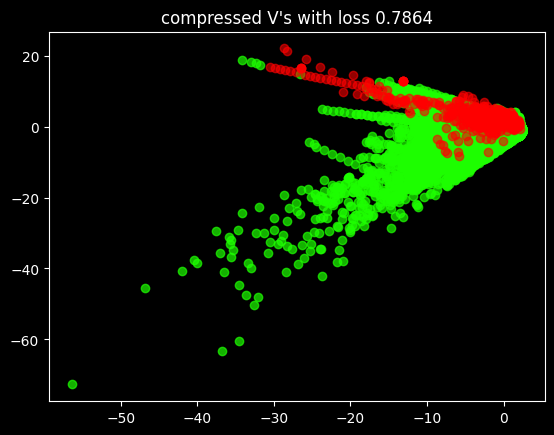

In [103]:
pca = PCA(n_components=2)
compressed_data = pca.fit_transform(fraud_data[[f'V{i}' for i in range(1, 29)]])
compressed_data = pd.DataFrame(compressed_data)
plt.style.use('dark_background')
data = compressed_data[fraud_data['Class']==0]
plt.scatter(data[0], data[1], color="#1eff00b2")
data = compressed_data[fraud_data['Class']==1]
plt.scatter(data[0], data[1], color="#ff000094")
plt.title(f"compressed V's with loss {1-pca.explained_variance_ratio_.sum():.4f}")
plt.show()

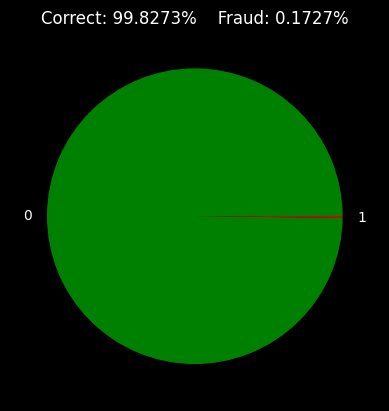

In [104]:
freq = fraud_data['Class'].value_counts().sort_index()
plt.pie(freq.values, labels=freq.index, colors=['green','red'])
plt.title(f"Correct: {100*freq[0]/freq.sum():.4f}%    Fraud: {100*freq[1]/freq.sum():.4f}%")
plt.show()